In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fontTools.diff import color
from prometheus_client import values

In [21]:
#Titanic
##Total count :

In [6]:
import seaborn as sns

df = sns.load_dataset("titanic")
df
# df.info()
# df.describe()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [7]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


In [8]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [12]:
df["survived"].value_counts()

survived
0    549
1    342
Name: count, dtype: int64

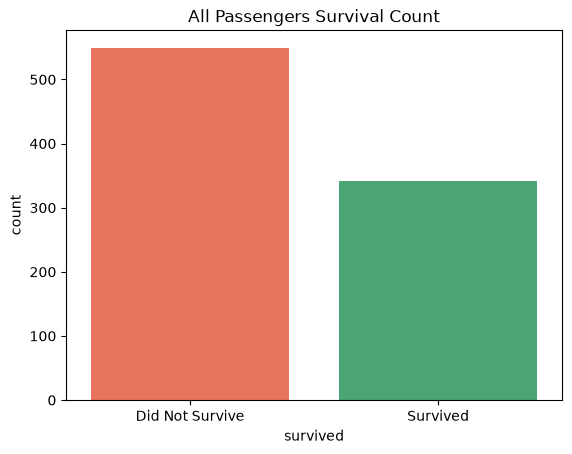

In [98]:
sns.countplot(
    data=titanic,
    x='survived',
    hue='survived',
    palette={0: 'tomato', 1: 'mediumseagreen'},
    legend=False)

plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.title('All Passengers Survival Count')
plt.show()

#this show the number of passengers who survived (342 out of 891) 38% of them

In [58]:
(df["who"]=="child").value_counts()

who
False    808
True      83
Name: count, dtype: int64

In [71]:
df[(df["survived"]==1) & (df["who"]=="child")].count()

survived       49
pclass         49
sex            49
age            49
sibsp          49
parch          49
fare           49
embarked       49
class          49
who            49
adult_male     49
deck           11
embark_town    49
alive          49
alone          49
dtype: int64

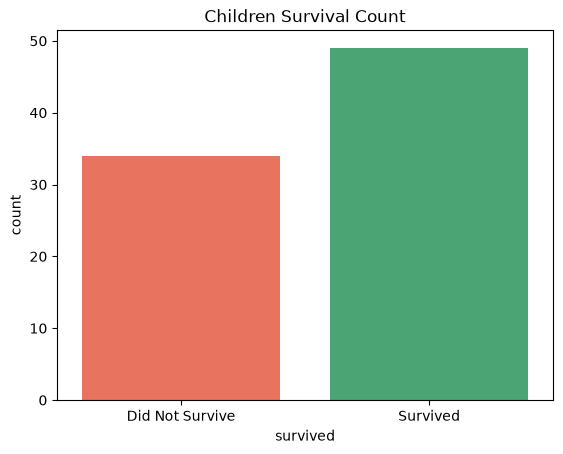

In [99]:
children = df[df['who'] == 'child']

sns.countplot(data=children,
    x='survived',
    hue='survived',
    palette={0: 'tomato', 1: 'mediumseagreen'},
    legend=False)

plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.title('Children Survival Count')
plt.show()

#out of 83 children only 49 survived or 59% of them

In [73]:
(df["sex"]=="female").value_counts()


sex
False    577
True     314
Name: count, dtype: int64

In [74]:
df[(df["survived"]==1) & (df["sex"]=="female")].count()

survived       233
pclass         233
sex            233
age            197
sibsp          233
parch          233
fare           233
embarked       231
class          233
who            233
adult_male     233
deck            91
embark_town    231
alive          233
alone          233
dtype: int64

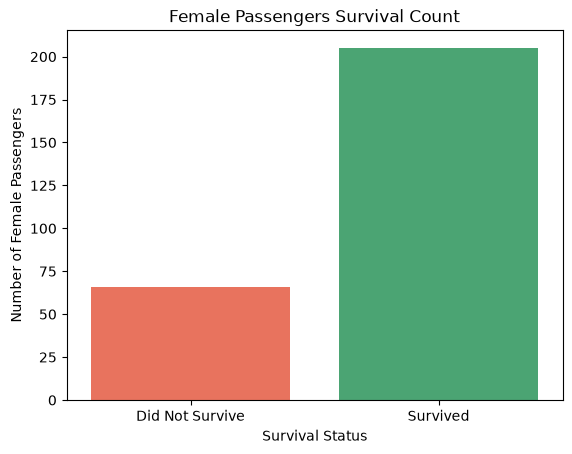

In [105]:
women = df[df['who'] == 'woman']
sns.countplot(
    data=women,
    x='survived',
    hue='survived',
    palette={0: 'tomato', 1: 'mediumseagreen'},
    legend=False
)

plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.title('Female Passengers Survival Count')
plt.xlabel('Survival Status')
plt.ylabel('Number of Female Passengers')

plt.show()

#out of 314 female on bord 233 survived or 74% of them


In [77]:
(df["adult_male"]==True).value_counts()

adult_male
True     537
False    354
Name: count, dtype: int64

In [78]:
df[(df["survived"]==1) & (df["adult_male"]==True)].count()


survived       88
pclass         88
sex            88
age            72
sibsp          88
parch          88
fare           88
embarked       88
class          88
who            88
adult_male     88
deck           38
embark_town    88
alive          88
alone          88
dtype: int64

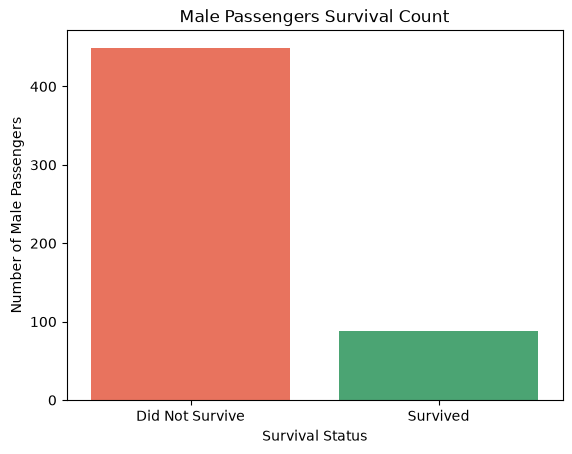

In [106]:
men = df[df['who'] == 'man']

sns.countplot(
    data=men,
    x='survived',
    hue='survived',
    palette={0: 'tomato', 1: 'mediumseagreen'},
    legend=False
)

plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.title('Male Passengers Survival Count')
plt.xlabel('Survival Status')
plt.ylabel('Number of Male Passengers')

plt.show()

#out of 537 male on bord only 88 survived or 16% of them

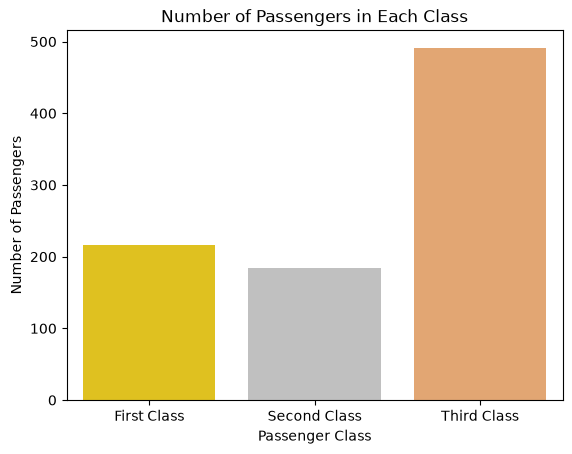

In [110]:
sns.countplot(
    data=titanic,
    x='pclass',
    hue='pclass',
    palette={
        1: 'gold',
        2: 'silver',
        3: 'sandybrown'
    },
    legend=False
)

plt.xticks([0, 1, 2], ['First Class', 'Second Class', 'Third Class'])
plt.title('Number of Passengers in Each Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')

plt.show()

In [80]:
(df["pclass"]==1).value_counts()


pclass
False    675
True     216
Name: count, dtype: int64

In [81]:
df[(df["survived"]==1) & (df["pclass"]==1)].count()


survived       136
pclass         136
sex            136
age            122
sibsp          136
parch          136
fare           136
embarked       134
class          136
who            136
adult_male     136
deck           117
embark_town    134
alive          136
alone          136
dtype: int64

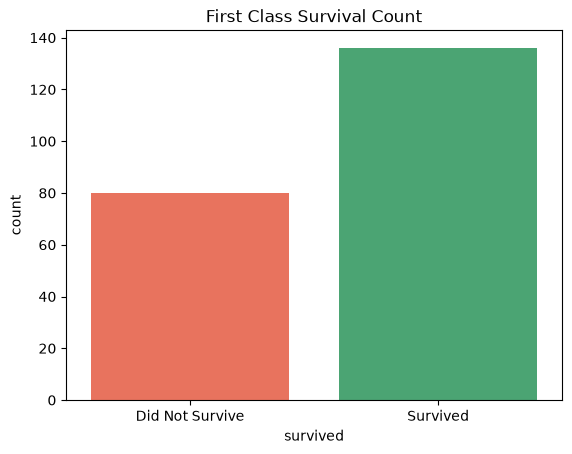

In [107]:
first_class = titanic[titanic['pclass'] == 1]

sns.countplot(
    data=first_class,
    x='survived',
    hue='survived',
    palette={0: 'tomato', 1: 'mediumseagreen'},
    legend=False
)

plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.title('First Class Survival Count')
plt.show()

##in first class 136 out of 216 people  survived which means more then 62%

In [82]:
(df["pclass"]==2).value_counts()


pclass
False    707
True     184
Name: count, dtype: int64

In [83]:
df[(df["survived"]==1) & (df["pclass"]==2)].count()


survived       87
pclass         87
sex            87
age            83
sibsp          87
parch          87
fare           87
embarked       87
class          87
who            87
adult_male     87
deck           13
embark_town    87
alive          87
alone          87
dtype: int64

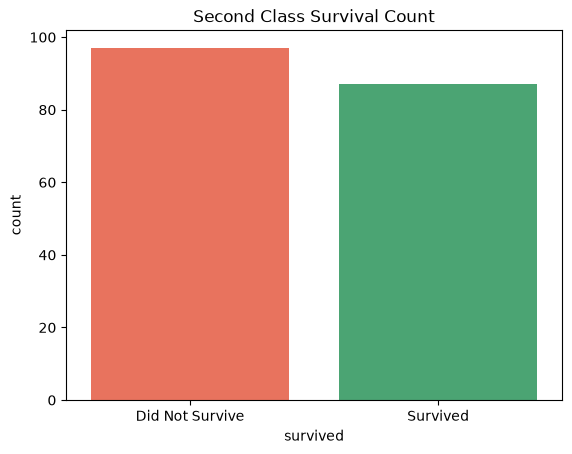

In [108]:
second_class = titanic[titanic['pclass'] == 2]

sns.countplot(
    data=second_class,
    x='survived',
    hue='survived',
    palette={0: 'tomato', 1: 'mediumseagreen'},
    legend=False
)

plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.title('Second Class Survival Count')
plt.show()

##in second class 87 out of 184 people  survived which means around 47%


In [84]:
(df["pclass"]==3).value_counts()


pclass
True     491
False    400
Name: count, dtype: int64

In [85]:
df[(df["survived"]==1) & (df["pclass"]==3)].count()


survived       119
pclass         119
sex            119
age             85
sibsp          119
parch          119
fare           119
embarked       119
class          119
who            119
adult_male     119
deck             6
embark_town    119
alive          119
alone          119
dtype: int64

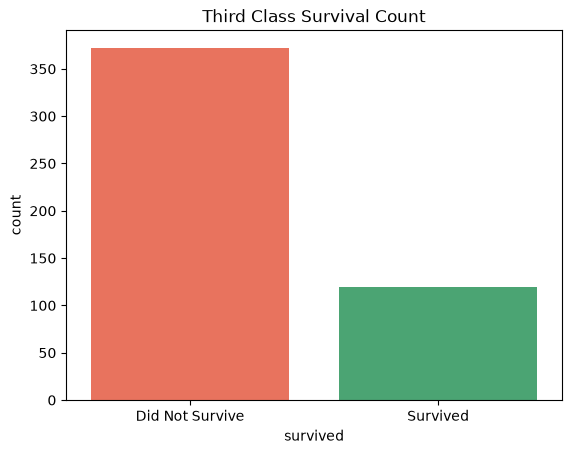

In [109]:
third_class = titanic[titanic['pclass'] == 3]

sns.countplot(
    data=third_class,
    x='survived',
    hue='survived',
    palette={0: 'tomato', 1: 'mediumseagreen'},
    legend=False
)

plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.title('Third Class Survival Count')
plt.show()

##in third class 119 out of 400 people survived which means only 29%
